# ME5411 Robot Vision and AI Project
> Group 33  
> Members: Loh Xin Zhi  

## Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from preprocessing import *
from utils import *

## Task 1: Display Image
Display the original image on screen. Experiment with contrast enhancement of the image. Comment on the results.

a. Display Original Image

In [2]:
CODE_DIR = Path.cwd()
test_img_path = CODE_DIR / "Test_Image_2026.bmp" 
test_img = cv2.imread(str(test_img_path))
test_img.shape

(367, 990, 3)

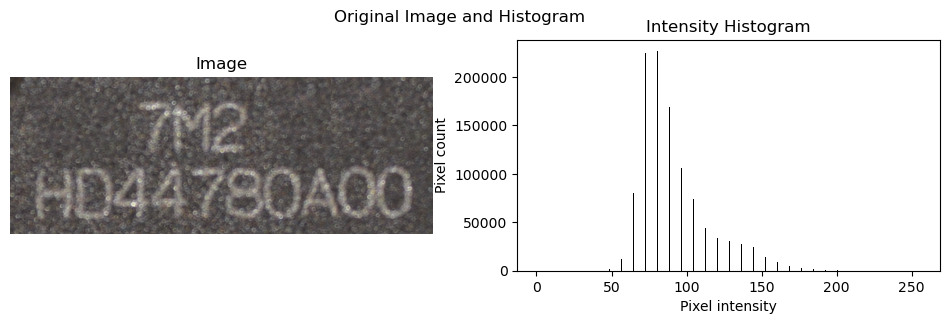

In [3]:
plot_img_hist(test_img, title="Original Image and Histogram")

b. Original Image in Grayscale

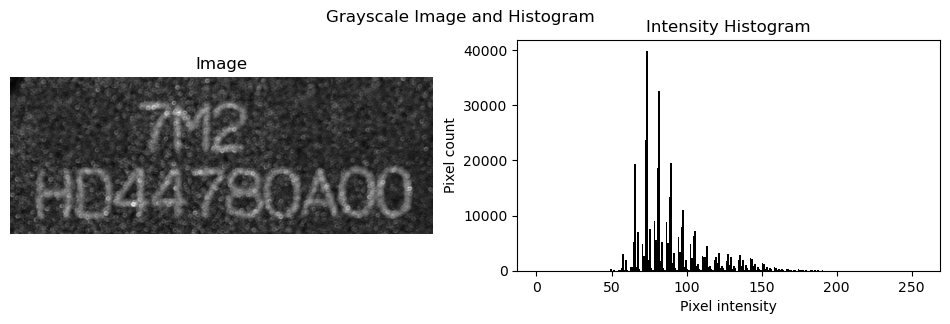

In [4]:
test_img_gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)
plot_img_hist(test_img_gray, title="Grayscale Image and Histogram")

c. Contrast Control

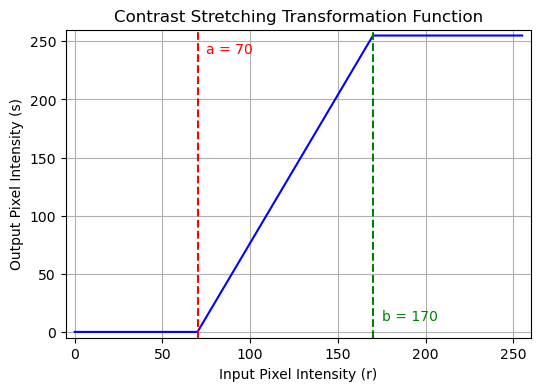

In [5]:
# Constrast Stretching
test_img_stretched = contrast_stretching(test_img_gray, a=70, b=170, show_transform=True)
# plot_img_hist(test_img_stretched, title="Contrast Stretched Image and Histogram")

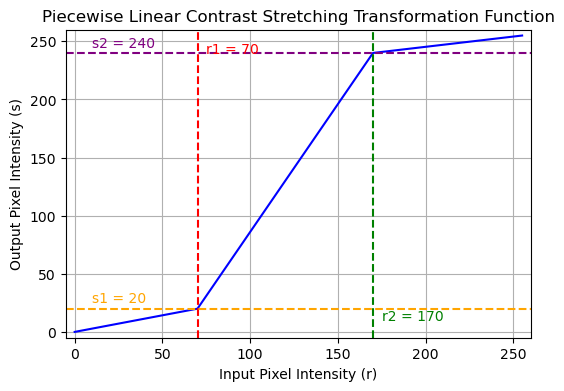

In [6]:
# Constrast Stretching Piecewise
test_img_stretched_piecewise = contrast_stretching_piecewise(test_img_gray, r1=70, r2=170, s1=20, s2=240, show_transform=True)
# plot_img_hist(test_img_stretched_piecewise, title="Contrast Stretched Piecewise Image and Histogram")

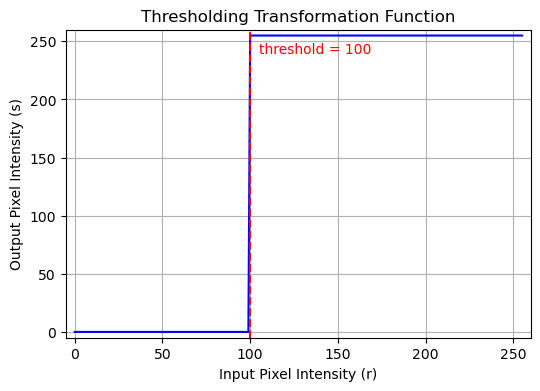

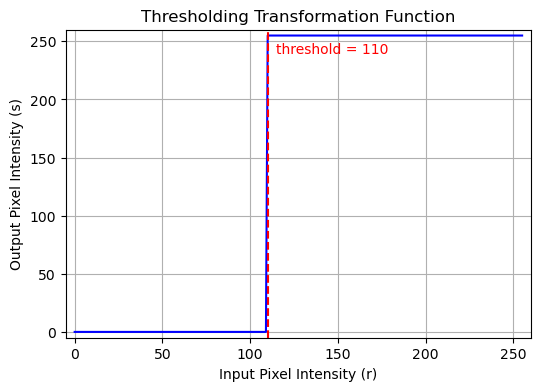

In [7]:
# Thresholding
test_img_thresholded_1 = thresholding(test_img_gray, threshold=100, show_transform=True)
# plot_img_hist(test_img_thresholded_1, title="Thresholded Image and Histogram")
test_img_thresholded_2 = thresholding(test_img_gray, threshold=110, show_transform=True)
# plot_img_hist(test_img_thresholded_2, title="Thresholded Image and Histogram")

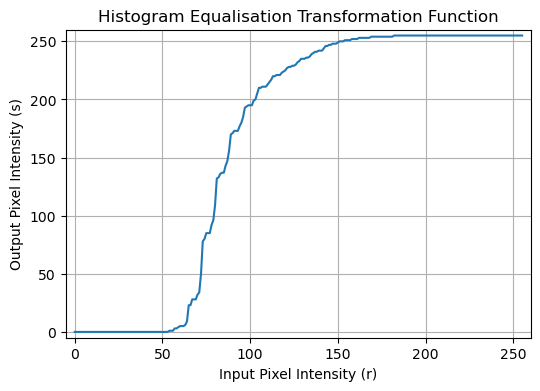

In [8]:
# Histogram equalization
test_img_eq = histogram_equalization(test_img_gray, show_transform=True)
# plot_img_hist(test_img_eq, title="Histogram Equalized Image and Histogram")

In [10]:
# CLAHE
test_img_clahe = clahe_equalization(test_img_gray, clip_limit=1.2, tile_grid_size=(4, 4))

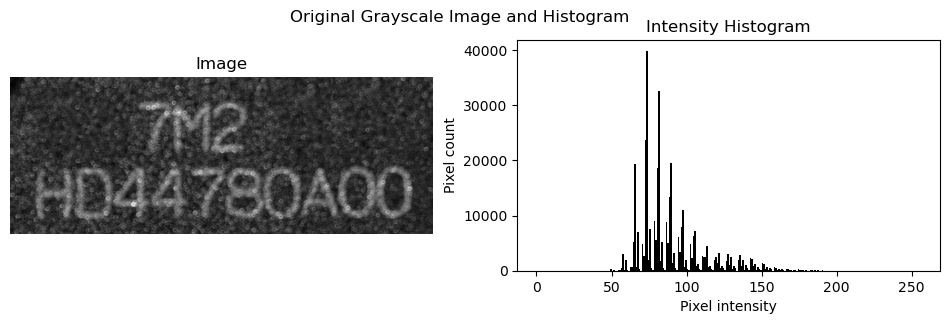

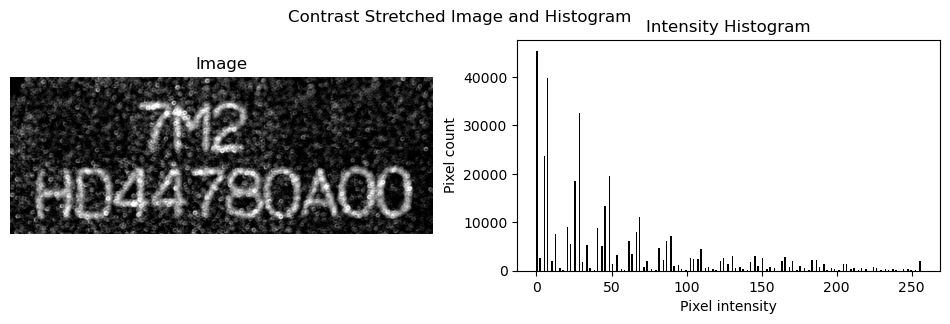

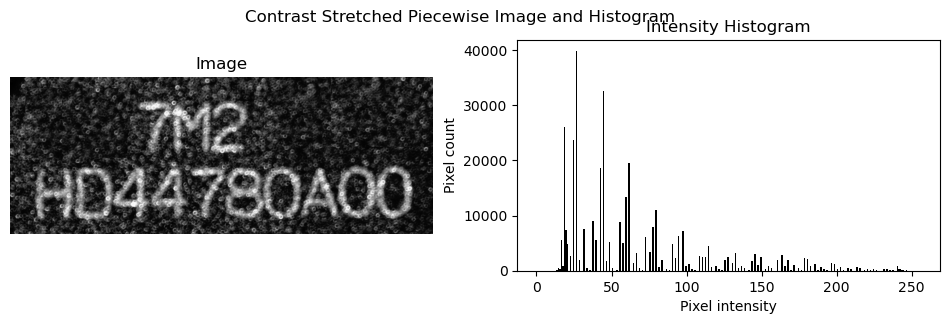

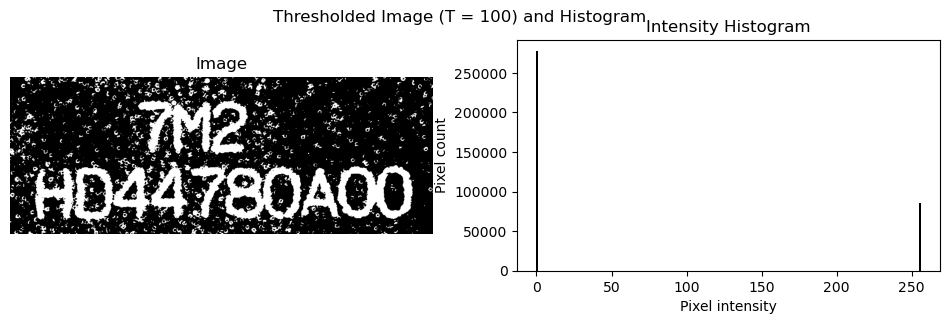

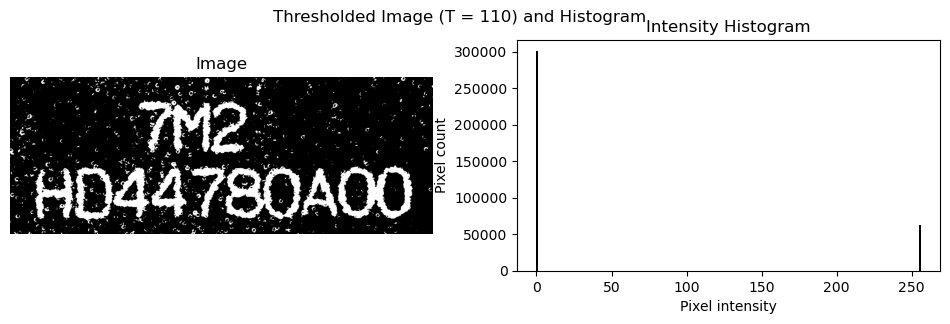

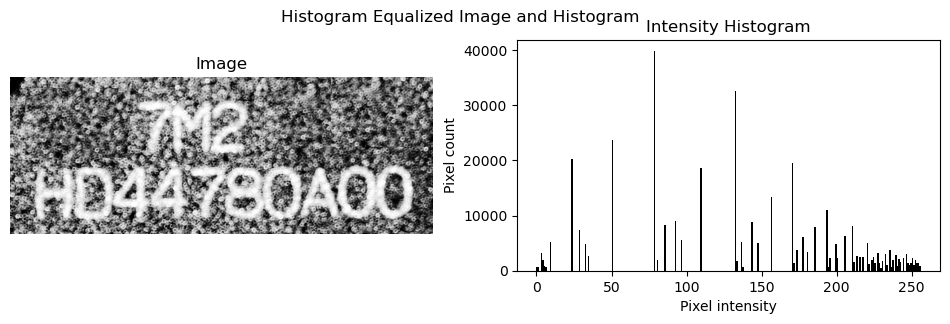

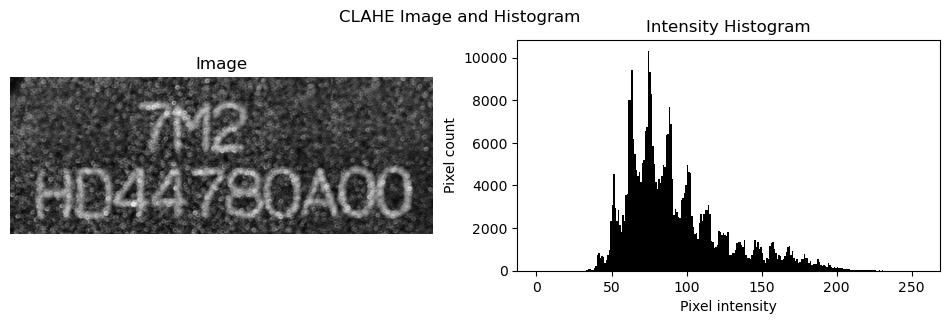

In [11]:
#plot all
plot_img_hist(test_img_gray, title="Original Grayscale Image and Histogram")
plot_img_hist(test_img_stretched, title="Contrast Stretched Image and Histogram")
plot_img_hist(test_img_stretched_piecewise, title="Contrast Stretched Piecewise Image and Histogram")
plot_img_hist(test_img_thresholded_1, title="Thresholded Image (T = 100) and Histogram")
plot_img_hist(test_img_thresholded_2, title="Thresholded Image (T = 110) and Histogram")
plot_img_hist(test_img_eq, title="Histogram Equalized Image and Histogram")
plot_img_hist(test_img_clahe, title="CLAHE Image and Histogram")

### Task 1 Discussion
Contrast methods are tested on the grayscale image:
1. Simple Contrast Stretching (a = 70, b = 170)
2. Piecewise Constrast Stretching (r1 = 70, r2 = 170, s1 = 20, s2 = 240)
3. 2x Brightness Thresholding (r1 = r2 = 100 and r1 = r2 = 110)
4. Histogram Equalization 
5. CLAHE (Contrast Limited Adaptive Histogram Equalisation) (clipLimit = 1.2, tileGridSize = (4,4))

#### Comments:
- Thresholding gives the best contrast, but also amplify the background noise. Noise is reduced (visually) when threhold is increased from 100 to 110, but this is dependent on the specific image.
- Contrast Stretching provide a good balance of increasing contrast while limiting noise contrast. The parameters of the stretching function is selected after analysing the image intensity histogram.
- Histogram Equalization transform the image without any parameter and attempts to equally distribute the brightness level. However, the due to the high noise level in the original image, the background noise contrast is also significantly amplified, resulting in a noiser image.
- CLAHE performs histogram equalization in small local regions, improving local contrast while limiting noise amplification.

Input image size: (367, 990), Output image size: (367, 990)


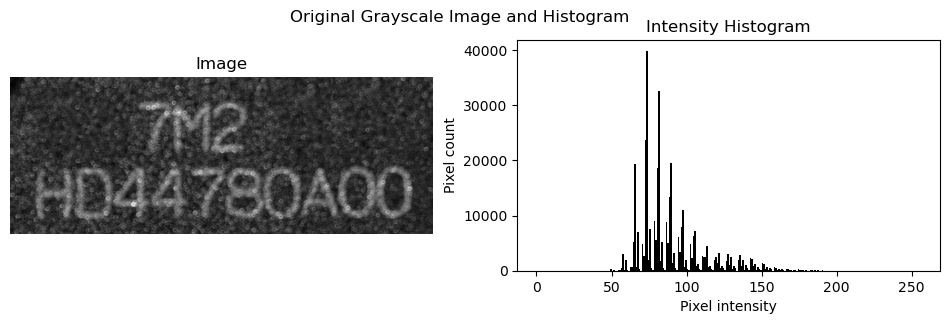

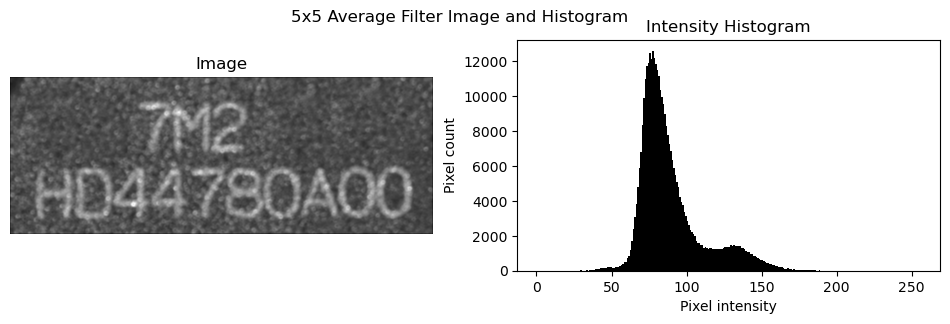

In [12]:
test_img_avg_filter_5 = average_filter(test_img_gray, 5)
plot_img_hist(test_img_gray, title="Original Grayscale Image and Histogram")
plot_img_hist(test_img_avg_filter_5, title="5x5 Average Filter Image and Histogram")
